## Nome:Mayara Cristina
## Matricula:574
-----


# **Atividade 17 - Testes não paramétricos**


## 1 -Teste dos Sinais (Amostras Pareadas)

Uma equipe de engenharia do Inatel deseja verificar se uma atualização de firmware reduz a latência de comunicação entre dispositivos IoT e um gateway. Para isso, foram registrados os tempos médios de resposta (em ms) dos mesmos 9 dispositivos antes e depois da atualização, sob as mesmas condições de teste. Considere o nível de significância de 5%.

| **Dispositivo** | **Antes (ms)** | **Depois (ms)** |
| --------------- | -------------- | --------------- |
| 1               | 126            | 117             |
| 2               | 141            | 130             |
| 3               | 134            | 129             |
| 4               | 158            | 145             |
| 5               | 120            | 124             |
| 6               | 147            | 139             |
| 7               | 136            | 125             |
| 8               | 152            | 152             |
| 9               | 129            | 121             |


In [2]:
import numpy as np

# Declare a tabela como numpy

dados = np.array([
    [126, 117],
    [141, 130],
    [134, 129],
    [158, 145],
    [120, 124],
    [147, 139],
    [136, 125],
    [152, 152],
    [129, 121]
])

print(dados)


[[126 117]
 [141 130]
 [134 129]
 [158 145]
 [120 124]
 [147 139]
 [136 125]
 [152 152]
 [129 121]]


##### 1.1 - Quais são as hipóteses do Teste dos Sinais?

**Resposta:**

H₀: A atualização do firmware não reduz a latência dos dispositivos.

H₁: A atualização do firmware reduz a latência dos dispositivos.

##### 1.2 - Identifique diferenças positivas, negativas e empates

In [3]:

diferencas = dados[:, 0] - dados[:, 1]

positivas = np.sum(diferencas > 0)
negativas = np.sum(diferencas < 0)
empates = np.sum(diferencas == 0)

print("Diferenças:", diferencas)
print("Positivas:", positivas)
print("Negativas:", negativas)
print("Empates:", empates)


Diferenças: [ 9 11  5 13 -4  8 11  0  8]
Positivas: 7
Negativas: 1
Empates: 1


##### 1.3 - Gere um gráfico de barras mostrando as diferenças

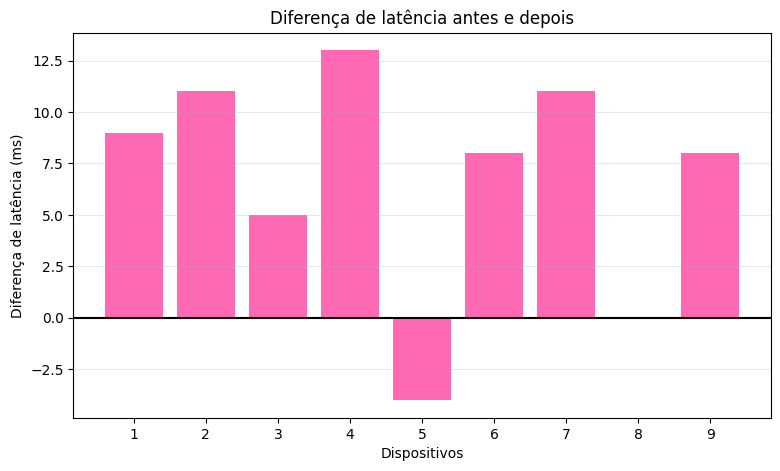

In [4]:

import matplotlib.pyplot as plt

dispositivos = np.arange(1, 10)

plt.figure(figsize=(9, 5))
plt.bar(dispositivos, diferencas, color='hotpink')

plt.axhline(0, color='black')
plt.xlabel('Dispositivos')
plt.ylabel('Diferença de latência (ms)')
plt.title('Diferença de latência antes e depois')
plt.xticks(dispositivos)
plt.grid(axis='y', alpha=0.3)

plt.show()


##### 1.4 - Calcule o p-valor

In [5]:

from scipy.stats import binomtest

n = positivas + negativas

resultado = binomtest(positivas, n, p=0.5, alternative='greater')

p_valor = resultado.pvalue

print("P-valor:", p_valor)


P-valor: 0.03515625


##### 1.5 - Conclusão

**Resposta:**

Como o p-valor (0,0352) é menor que o nível de significância de 5% (0,05), rejeitamos a hipótese nula (H₀). Portanto, existem evidências estatísticas suficientes para concluir que a atualização do firmware reduziu a latência de comunicação dos dispositivos IoT.